# Financial Statement Anomaly Analysis & Risk Screening

**Project type:** Finance-domain analytics + lightweight supervised machine learning  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, XGBoost, Optuna

## Business question
Can we prioritize company-year financial records for analyst review using accounting data and financial ratios associated with reported financial misstatements?

> **Responsible-use note:** A model score is a screening signal, not proof of fraud or wrongdoing. The target is an enforcement-linked label from a historical research dataset. A negative label does not prove that a company had no misstatement.

This notebook is intentionally kept concise (under 40 cells). It compares a naïve baseline, an interpretable Logistic Regression model, and an Optuna-tuned XGBoost model. The final test period remains untouched during model selection.

## 1. Dataset and project setup

The CSV is `data_FraudDetection_JAR2020.csv`, published with research by Bao, Ke, Li, Yu, and Zhang (2020), *Detecting Accounting Fraud in Publicly Traded U.S. Firms Using a Machine Learning Approach*, Journal of Accounting Research.

Place the CSV beside this notebook before running it. The dataset is not included in the project ZIP; this keeps the bundle lightweight and avoids accidentally committing a large dataset to GitHub.

In [2]:
%pip install -q optuna xgboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.6 MB/s eta 0:00:00


In [3]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import optuna

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    precision_recall_curve, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')

print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('xgboost:', xgboost.__version__)
print('optuna:', optuna.__version__)

pandas: 2.2.3
scikit-learn: 1.6.1
xgboost: 3.4.1
optuna: 5.0.0


In [4]:
DATA_FILENAME = 'data_FraudDetection_JAR2020.csv'
possible_paths = [
    Path(DATA_FILENAME),
    Path.cwd() / DATA_FILENAME,
    Path('/mnt/data') / DATA_FILENAME,  # convenient in hosted notebook environments
]
DATA_PATH = next((p for p in possible_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f'Could not find {DATA_FILENAME}. Put the CSV in the same folder as this notebook.'
    )

df = pd.read_csv(DATA_PATH)
print(f'Loaded: {DATA_PATH}')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head()

Loaded: data_FraudDetection_JAR2020.csv
Shape: 146,045 rows × 46 columns


,fyear,gvkey,p_aaer,misstate,act,ap,at,ceq,che,cogs,...,soft_assets,ch_cs,ch_cm,ch_roa,issue,bm,dpi,reoa,EBIT,ch_fcf
0,1990,1009,NaN,0,10.047,3.736,32.335,6.262,0.002,30.633,...,0.312448,0.095082,0.082631,-0.019761,1,0.413170,0.873555,0.167620,0.161961,-0.042140
1,1990,1011,NaN,0,1.247,0.803,7.784,0.667,0.171,1.125,...,0.315904,0.188832,-0.211389,-0.117832,1,0.157887,0.745139,-0.428957,-0.157888,0.100228
2,1990,1017,NaN,0,55.040,3.601,118.120,44.393,3.132,107.343,...,0.605342,0.097551,-0.105780,0.091206,1,2.231337,1.015131,0.394768,0.063681,0.066348
3,1990,1021,NaN,0,24.684,3.948,34.591,7.751,0.411,31.214,...,0.793068,-0.005725,-0.249704,0.017545,1,1.043582,1.026261,0.094822,0.088347,-0.017358
4,1990,1028,NaN,0,17.325,3.520,27.542,-12.142,1.017,32.662,...,0.869182,-0.231536,-1.674893,-0.466667,0,-1.602508,0.598443,-0.942379,-0.700821,0.130349


In [5]:
print('Columns:', df.columns.tolist())
print('\nData types:')
display(df.dtypes.to_frame('dtype'))
print('\nNumeric summary (sample):')
display(df.describe().T.head(12))

Columns: ['fyear', 'gvkey', 'p_aaer', 'misstate', 'act', 'ap', 'at', 'ceq', 'che', 'cogs', 'csho', 'dlc', 'dltis', 'dltt', 'dp', 'ib', 'invt', 'ivao', 'ivst', 'lct', 'lt', 'ni', 'ppegt', 'pstk', 're', 'rect', 'sale', 'sstk', 'txp', 'txt', 'xint', 'prcc_f', 'dch_wc', 'ch_rsst', 'dch_rec', 'dch_inv', 'soft_assets', 'ch_cs', 'ch_cm', 'ch_roa', 'issue', 'bm', 'dpi', 'reoa', 'EBIT', 'ch_fcf']

Data types:


,dtype
fyear,int64
gvkey,int64
p_aaer,float64
misstate,int64
act,float64
ap,float64
at,float64
ceq,float64
che,float64
cogs,float64



Numeric summary (sample):


,count,mean,std,min,25%,50%,75%,max
fyear,146045.0,2002.011702,6.959894,1990.000,1996.000,2002.000,2008.000,2014.000
gvkey,146045.0,54243.435516,59937.455765,1004.000,10658.000,25088.000,66586.000,317264.000
p_aaer,964.0,2503.840249,912.093250,371.000,1803.000,2620.500,3180.000,3996.000
misstate,146045.0,0.006601,0.080976,0.000,0.000,0.000,0.000,1.000
act,146045.0,737.847759,3744.542368,-0.254,8.277,47.501,249.832,152629.000
ap,146045.0,181.993488,1047.546104,0.000,1.151,6.462,42.259,39903.000
at,146045.0,2374.041576,11957.736980,0.000,18.281,105.346,672.929,410074.000
ceq,146045.0,887.126243,5056.948150,-25560.000,6.337,47.308,271.547,284434.000
che,146045.0,218.657186,1330.490185,-34.000,1.144,9.373,60.286,85709.000
cogs,146045.0,1302.280756,7870.665783,-366.645,6.795,53.382,372.730,435726.253


In [6]:
TARGET = 'misstate'
YEAR_COL = 'fyear'
COMPANY_COL = 'gvkey'
LEAKAGE_COL = 'p_aaer'

assert {TARGET, YEAR_COL, COMPANY_COL, LEAKAGE_COL}.issubset(df.columns)
assert df[TARGET].notna().all(), 'Target contains missing values; inspect before modelling.'
assert set(df[TARGET].unique()).issubset({0, 1}), 'Target must be binary.'

print('Fiscal-year range:', int(df[YEAR_COL].min()), 'to', int(df[YEAR_COL].max()))
print('Unique companies:', f'{df[COMPANY_COL].nunique():,}')
print('Target counts:')
display(df[TARGET].value_counts().rename(index={0: 'misstate=0', 1: 'misstate=1'}).to_frame('records'))
print(f"Positive-label rate: {df[TARGET].mean():.3%}")

Fiscal-year range: 1990 to 2014
Unique companies: 18,444
Target counts:


,records
misstate,
misstate=0,145081
misstate=1,964


Positive-label rate: 0.660%


In [7]:
missing = df.isna().mean().sort_values(ascending=False)
quality_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
}).sort_values('missing_pct', ascending=False)
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Duplicate company-year keys:', int(df.duplicated([COMPANY_COL, YEAR_COL]).sum()))
display(quality_summary.head(15))

Exact duplicate rows: 0
Duplicate company-year keys: 0


,missing_count,missing_pct
p_aaer,145081,99.34
ch_cm,17107,11.71
ch_cs,15918,10.90
ch_roa,12678,8.68
dpi,9228,6.32
ch_fcf,5407,3.70
ch_rsst,4851,3.32
dch_wc,4759,3.26
dch_rec,4743,3.25
dch_inv,4615,3.16


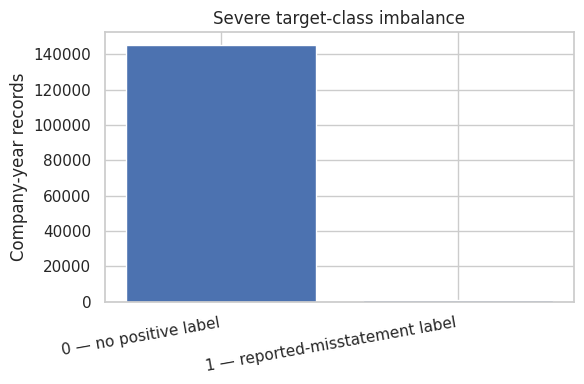

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df[TARGET].value_counts().sort_index()
ax.bar(['0 — no positive label', '1 — reported-misstatement label'], counts.reindex([0, 1]).values)
ax.set_title('Severe target-class imbalance')
ax.set_ylabel('Company-year records')
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

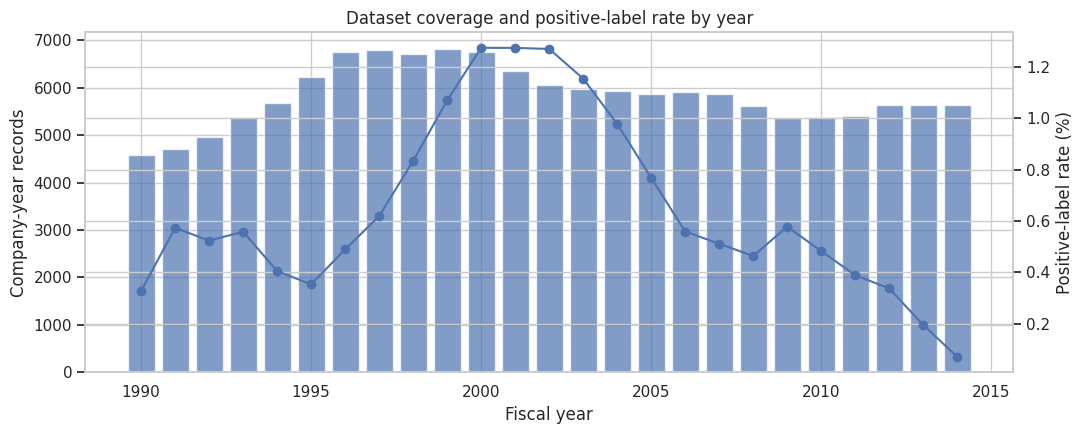

,records,positive_labels,positive_rate_pct
fyear,,,
2005,5863,45,0.767525
2006,5908,33,0.558565
2007,5868,30,0.511247
2008,5612,26,0.463293
2009,5367,31,0.577604
2010,5389,26,0.482464
2011,5404,21,0.388601
2012,5630,19,0.337478
2013,5647,11,0.194794


In [9]:
year_counts = df.groupby(YEAR_COL)[TARGET].agg(records='size', positive_labels='sum')
year_counts['positive_rate_pct'] = 100 * year_counts['positive_labels'] / year_counts['records']
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(year_counts.index, year_counts['records'], alpha=0.7, label='Records')
ax1.set_ylabel('Company-year records')
ax1.set_xlabel('Fiscal year')
ax2 = ax1.twinx()
ax2.plot(year_counts.index, year_counts['positive_rate_pct'], marker='o', linewidth=1.5, label='Positive-label rate')
ax2.set_ylabel('Positive-label rate (%)')
ax1.set_title('Dataset coverage and positive-label rate by year')
fig.tight_layout()
plt.show()
display(year_counts.tail(10))

In [10]:
RATIO_COLS = [
    'dch_wc', 'ch_rsst', 'dch_rec', 'dch_inv', 'soft_assets', 'ch_cs', 'ch_cm',
    'ch_roa', 'issue', 'bm', 'dpi', 'reoa', 'EBIT', 'ch_fcf'
]
RATIO_COLS = [c for c in RATIO_COLS if c in df.columns]
print('Financial-ratio fields used for focused EDA:', RATIO_COLS)
print('Total candidate predictors before exclusions:', len(df.columns) - 4)

Financial-ratio fields used for focused EDA: ['dch_wc', 'ch_rsst', 'dch_rec', 'dch_inv', 'soft_assets', 'ch_cs', 'ch_cm', 'ch_roa', 'issue', 'bm', 'dpi', 'reoa', 'EBIT', 'ch_fcf']
Total candidate predictors before exclusions: 42


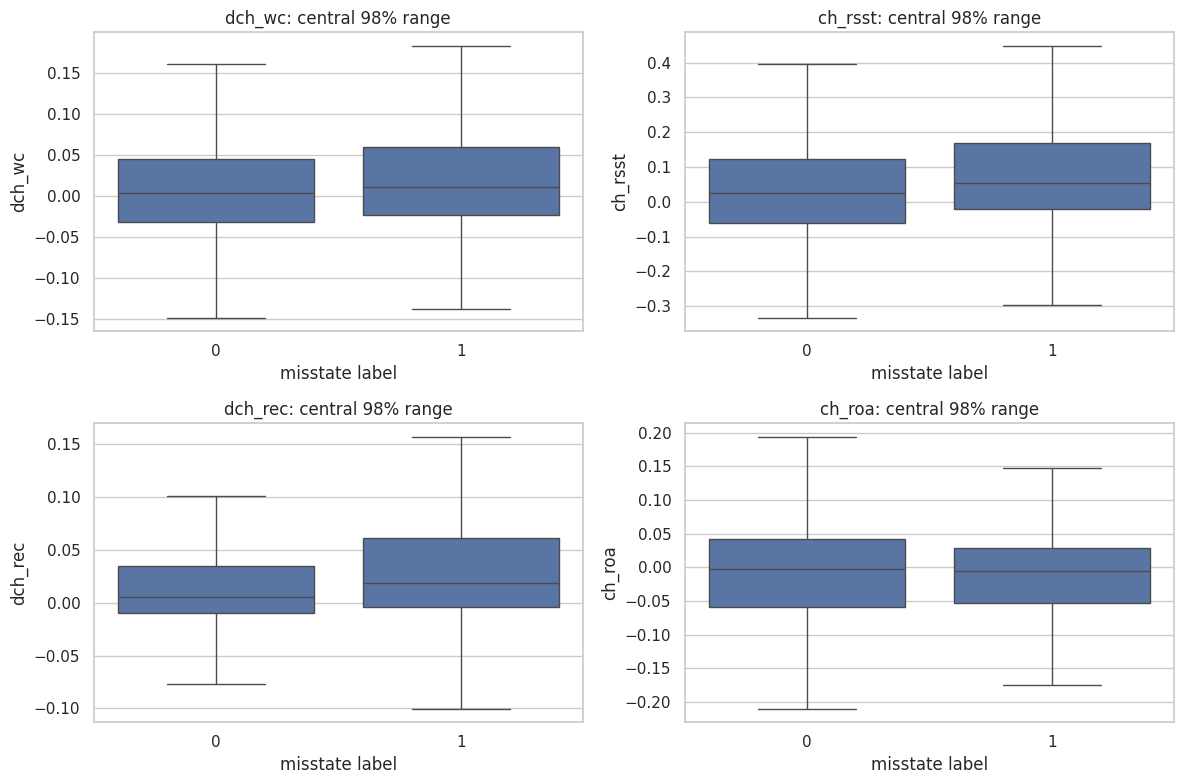

In [11]:
# Robust display: winsorization is not applied to model inputs here; plots use 1st–99th percentiles only.
plot_cols = [c for c in ['dch_wc', 'ch_rsst', 'dch_rec', 'ch_roa'] if c in df.columns]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), plot_cols):
    bounds = df[col].quantile([0.01, 0.99])
    temp = df[[TARGET, col]].copy()
    temp[col] = temp[col].clip(bounds.iloc[0], bounds.iloc[1])
    sns.boxplot(data=temp, x=TARGET, y=col, showfliers=False, ax=ax)
    ax.set_title(f'{col}: central 98% range')
    ax.set_xlabel('misstate label')
plt.tight_layout()
plt.show()

In [12]:
ratio_medians = df.groupby(TARGET)[RATIO_COLS].median().T
ratio_medians.columns = ['label_0_median', 'label_1_median']
ratio_medians['median_difference_1_minus_0'] = ratio_medians['label_1_median'] - ratio_medians['label_0_median']
display(ratio_medians.sort_values('median_difference_1_minus_0', key=lambda s: s.abs(), ascending=False))

,label_0_median,label_1_median,median_difference_1_minus_0
soft_assets,0.523436,0.683939,0.160503
reoa,-0.009038,0.083526,0.092564
ch_cs,0.067556,0.150633,0.083077
bm,0.442625,0.377073,-0.065553
ch_rsst,0.026110,0.052516,0.026407
ch_fcf,-0.026005,-0.050501,-0.024496
EBIT,0.043509,0.064219,0.020710
dch_rec,0.004950,0.018286,0.013337
dch_wc,0.003538,0.010606,0.007068
dpi,0.974261,0.980179,0.005918


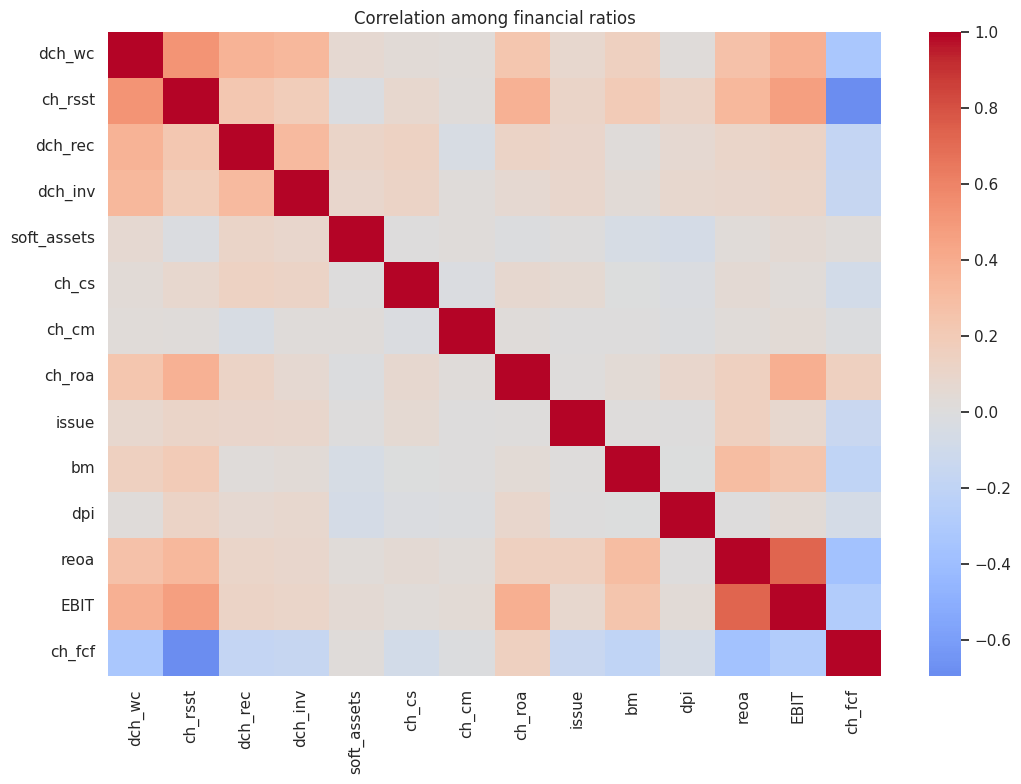

In [13]:
if len(RATIO_COLS) >= 2:
    corr = df[RATIO_COLS].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(11, 8))
    sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, square=False)
    ax.set_title('Correlation among financial ratios')
    plt.tight_layout()
    plt.show()

## 2. Leakage prevention and chronological split

- `misstate` is the target.
- `p_aaer` is excluded because it is related to AAER/serial-misstatement handling and could leak target information.
- `gvkey` is a company identifier, not a generalizable predictor.
- `fyear` is kept for chronological splitting and reporting, but is excluded from model features.
- All imputation/scaling is fitted inside model pipelines using training data only.

We use fiscal years **1990–2003 for training**, **2004–2007 for validation**, and **2008–2014 for the final test**. The exact year coverage is checked against the loaded file.

In [14]:
EXCLUDED_FROM_FEATURES = {TARGET, YEAR_COL, COMPANY_COL, LEAKAGE_COL}
feature_cols = [c for c in df.columns if c not in EXCLUDED_FROM_FEATURES]
assert len(feature_cols) > 0
assert LEAKAGE_COL not in feature_cols and COMPANY_COL not in feature_cols and YEAR_COL not in feature_cols

TRAIN_END = 2003
VAL_START, VAL_END = 2004, 2007
TEST_START, TEST_END = 2008, int(df[YEAR_COL].max())
assert df[YEAR_COL].min() <= TRAIN_END < VAL_START <= VAL_END < TEST_START <= TEST_END

train_df = df[df[YEAR_COL] <= TRAIN_END].copy()
val_df = df[df[YEAR_COL].between(VAL_START, VAL_END)].copy()
test_df = df[df[YEAR_COL].between(TEST_START, TEST_END)].copy()
assert len(train_df) and len(val_df) and len(test_df)

X_train = train_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = train_df[TARGET].astype(int)
X_val = val_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_val = val_df[TARGET].astype(int)
X_test = test_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_test = test_df[TARGET].astype(int)

print(f'Predictor columns: {len(feature_cols)}')
print('Excluded columns:', sorted(EXCLUDED_FROM_FEATURES))

Predictor columns: 42
Excluded columns: ['fyear', 'gvkey', 'misstate', 'p_aaer']


In [15]:
def split_summary(name, part, y):
    return {
        'split': name,
        'rows': len(part),
        'year_min': int(part[YEAR_COL].min()),
        'year_max': int(part[YEAR_COL].max()),
        'positive_labels': int(y.sum()),
        'positive_rate_pct': round(100 * float(y.mean()), 3),
    }

split_table = pd.DataFrame([
    split_summary('train', train_df, y_train),
    split_summary('validation', val_df, y_val),
    split_summary('test', test_df, y_test),
])
display(split_table)

,split,rows,year_min,year_max,positive_labels,positive_rate_pct
0,train,83796,1990,2003,660,0.788
1,validation,23573,2004,2007,166,0.704
2,test,38676,2008,2014,138,0.357


## 3. Baseline and evaluation helpers

The main ranking metric is **average precision (AP, often referred to as PR-AUC in applied projects)**. Accuracy is not a useful headline metric when positive labels are rare. We also report ROC-AUC and the utility of the **top 5% review queue**. Top-5% metrics answer: if an analyst can only review 5% of records, how many labelled positives are captured?

In [16]:
def make_imputer():
    # Missingness indicators can be informative; empty columns are preserved for stable schemas.
    return SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)


def make_logistic_pipeline():
    return Pipeline([
        ('imputer', make_imputer()),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
    ])


def make_xgb_pipeline(params, scale_pos_weight):
    model = XGBClassifier(
        objective='binary:logistic', eval_metric='aucpr', tree_method='hist',
        n_jobs=-1, random_state=RANDOM_STATE, verbosity=0,
        scale_pos_weight=scale_pos_weight, **params
    )
    return Pipeline([('imputer', make_imputer()), ('model', model)])


def positive_scores(fitted_pipeline, X):
    model = fitted_pipeline.named_steps['model']
    positive_index = list(model.classes_).index(1)
    return fitted_pipeline.predict_proba(X)[:, positive_index]


def ranking_metrics(y_true, scores, review_fraction=0.05):
    y_arr = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    k = max(1, int(np.ceil(len(y_arr) * review_fraction)))
    top_idx = np.argsort(scores)[::-1][:k]
    positives = int(y_arr.sum())
    captured = int(y_arr[top_idx].sum())
    return {
        'average_precision': average_precision_score(y_arr, scores),
        'roc_auc': roc_auc_score(y_arr, scores) if len(np.unique(y_arr)) > 1 else np.nan,
        'review_queue_size': k,
        'positives_in_top_5pct': captured,
        'precision_at_top_5pct': captured / k,
        'recall_at_top_5pct': captured / positives if positives else np.nan,
    }


def class_ratio(y):
    positives = int(np.sum(np.asarray(y) == 1))
    negatives = int(np.sum(np.asarray(y) == 0))
    return negatives / max(positives, 1)

In [17]:
dummy_model = DummyClassifier(strategy='prior')
dummy_model.fit(X_train, y_train)
dummy_val_scores = dummy_model.predict_proba(X_val)[:, list(dummy_model.classes_).index(1)]
dummy_val_metrics = ranking_metrics(y_val, dummy_val_scores)
print('Naïve baseline — validation metrics')
display(pd.DataFrame([dummy_val_metrics], index=['DummyClassifier (prior)']))

Naïve baseline — validation metrics


,average_precision,roc_auc,review_queue_size,positives_in_top_5pct,precision_at_top_5pct,recall_at_top_5pct
DummyClassifier (prior),0.007042,0.5,1179,7,0.005937,0.042169


In [18]:
lr_model = make_logistic_pipeline()
lr_model.fit(X_train, y_train)
lr_val_scores = positive_scores(lr_model, X_val)
lr_val_metrics = ranking_metrics(y_val, lr_val_scores)
print('Logistic Regression — validation metrics')
display(pd.DataFrame([lr_val_metrics], index=['Logistic Regression']))

Logistic Regression — validation metrics


,average_precision,roc_auc,review_queue_size,positives_in_top_5pct,precision_at_top_5pct,recall_at_top_5pct
Logistic Regression,0.013729,0.689435,1179,18,0.015267,0.108434


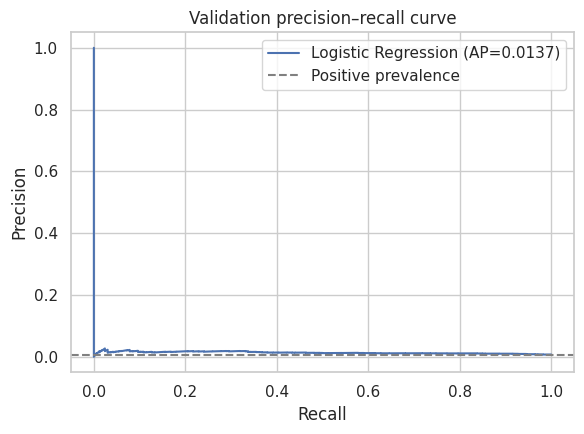

In [19]:
precision, recall, _ = precision_recall_curve(y_val, lr_val_scores)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(recall, precision, label=f'Logistic Regression (AP={lr_val_metrics["average_precision"]:.4f})')
ax.axhline(y_val.mean(), linestyle='--', color='grey', label='Positive prevalence')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Validation precision–recall curve')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Tune XGBoost with Optuna

Optuna optimizes validation average precision. We use a deliberately bounded search (20 trials) to keep the project manageable. Hyperparameter tuning is performed only on the development/validation years; the final 2008–2014 test period is not used for tuning or winner selection.

In [20]:
BASE_SCALE_POS_WEIGHT = class_ratio(y_train)


def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 350, step=50),
        'max_depth': trial.suggest_int('max_depth', 2, 5),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 20.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.65, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.60, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 20.0, log=True),
        'gamma': trial.suggest_float('gamma', 0.0, 2.0),
    }
    imbalance_multiplier = trial.suggest_float('imbalance_multiplier', 0.5, 2.0)
    model = make_xgb_pipeline(params, BASE_SCALE_POS_WEIGHT * imbalance_multiplier)
    model.fit(X_train, y_train)
    scores = positive_scores(model, X_val)
    return average_precision_score(y_val, scores)

study = optuna.create_study(direction='maximize', study_name='xgboost_average_precision', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
N_TRIALS = 20
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
print('Completed trials:', len(study.trials))
print('Best validation average precision:', round(study.best_value, 6))

  0%|          | 0/20 [00:00<?, ?it/s]

Completed trials: 20
Best validation average precision: 0.03479


,best_value
n_estimators,350.000000
max_depth,5.000000
learning_rate,0.078031
min_child_weight,10.025071
subsample,0.785775
colsample_bytree,0.703487
reg_lambda,0.261775
gamma,1.795356
imbalance_multiplier,0.582630


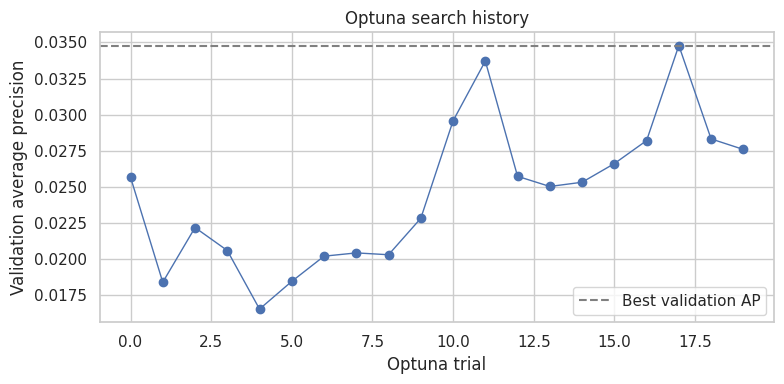

In [21]:
display(pd.DataFrame([study.best_params]).T.rename(columns={0: 'best_value'}))
trials_df = study.trials_dataframe(attrs=('number', 'value', 'state'))
fig, ax = plt.subplots(figsize=(8, 4))
valid_trials = trials_df[trials_df['state'] == 'COMPLETE']
ax.plot(valid_trials['number'], valid_trials['value'], marker='o', linewidth=1)
ax.axhline(study.best_value, linestyle='--', color='grey', label='Best validation AP')
ax.set_xlabel('Optuna trial')
ax.set_ylabel('Validation average precision')
ax.set_title('Optuna search history')
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
best_xgb_params = {k: v for k, v in study.best_params.items() if k != 'imbalance_multiplier'}
best_xgb_scale = BASE_SCALE_POS_WEIGHT * study.best_params['imbalance_multiplier']
xgb_model = make_xgb_pipeline(best_xgb_params, best_xgb_scale)
xgb_model.fit(X_train, y_train)
xgb_val_scores = positive_scores(xgb_model, X_val)
xgb_val_metrics = ranking_metrics(y_val, xgb_val_scores)
print('Tuned XGBoost — validation metrics')
display(pd.DataFrame([xgb_val_metrics], index=['XGBoost + Optuna']))

Tuned XGBoost — validation metrics


,average_precision,roc_auc,review_queue_size,positives_in_top_5pct,precision_at_top_5pct,recall_at_top_5pct
XGBoost + Optuna,0.03479,0.760411,1179,37,0.031383,0.222892


,average_precision,roc_auc,review_queue_size,positives_in_top_5pct,precision_at_top_5pct,recall_at_top_5pct
model,,,,,,
XGBoost + Optuna,0.034790,0.760411,1179,37,0.031383,0.222892
Logistic Regression,0.013729,0.689435,1179,18,0.015267,0.108434
DummyClassifier (prior),0.007042,0.500000,1179,7,0.005937,0.042169


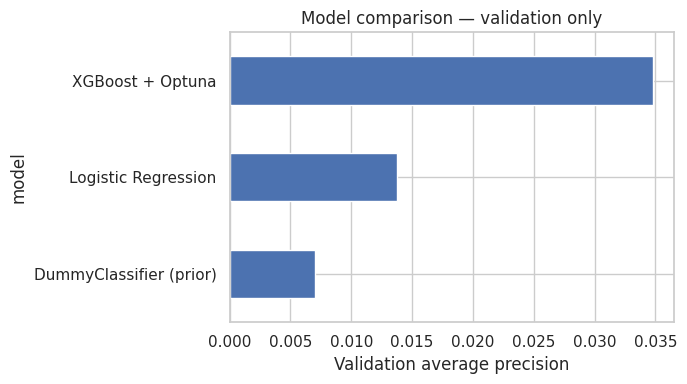

In [23]:
validation_comparison = pd.DataFrame([
    {'model': 'DummyClassifier (prior)', **dummy_val_metrics},
    {'model': 'Logistic Regression', **lr_val_metrics},
    {'model': 'XGBoost + Optuna', **xgb_val_metrics},
]).set_index('model').sort_values('average_precision', ascending=False)
display(validation_comparison)

plt.figure(figsize=(7, 4))
validation_comparison['average_precision'].sort_values().plot(kind='barh')
plt.xlabel('Validation average precision')
plt.title('Model comparison — validation only')
plt.tight_layout()
plt.show()

In [24]:
# Select between predictive models using validation AP only. The DummyClassifier remains a benchmark.
validation_model_scores = {
    'Logistic Regression': lr_val_metrics['average_precision'],
    'XGBoost + Optuna': xgb_val_metrics['average_precision'],
}
selected_model_name = max(validation_model_scores, key=validation_model_scores.get)
print('Selected using validation average precision:', selected_model_name)

val_winner_scores = lr_val_scores if selected_model_name == 'Logistic Regression' else xgb_val_scores
val_winner_metrics = ranking_metrics(y_val, val_winner_scores)
print('Validation top-5% review queue:')
print(f"Queue size: {val_winner_metrics['review_queue_size']:,} records")
print(f"Labelled positives captured: {val_winner_metrics['positives_in_top_5pct']:,} of {int(y_val.sum()):,}")
print(f"Precision@5%: {val_winner_metrics['precision_at_top_5pct']:.3%}")
print(f"Recall@5%: {val_winner_metrics['recall_at_top_5pct']:.3%}")

Selected using validation average precision: XGBoost + Optuna
Validation top-5% review queue:
Queue size: 1,179 records
Labelled positives captured: 37 of 166
Precision@5%: 3.138%
Recall@5%: 22.289%


## 5. Final test evaluation and model artifact

The winner is chosen using validation AP only. We then refit that model on the combined training + validation period, and evaluate once on the later test period. The test results are for estimating future-period performance, not for further model tuning.

In [25]:
X_dev = pd.concat([X_train, X_val], axis=0)
y_dev = pd.concat([y_train, y_val], axis=0)

if selected_model_name == 'Logistic Regression':
    final_model = make_logistic_pipeline()
    final_model.fit(X_dev, y_dev)
    artifact_model_type = 'Logistic Regression'
else:
    dev_scale_pos_weight = class_ratio(y_dev) * study.best_params['imbalance_multiplier']
    final_model = make_xgb_pipeline(best_xgb_params, dev_scale_pos_weight)
    final_model.fit(X_dev, y_dev)
    artifact_model_type = 'XGBoost + Optuna'

final_test_scores = positive_scores(final_model, X_test)
final_test_metrics = ranking_metrics(y_test, final_test_scores)
print('FINAL TEST RESULTS — untouched years', TEST_START, 'to', TEST_END)
display(pd.DataFrame([final_test_metrics], index=[artifact_model_type]).T.rename(columns={0: 'value'}))

ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, ARTIFACT_DIR / 'model.joblib')
model_config = {
    'project_name': 'Financial Statement Anomaly Analysis & Risk Screening',
    'model_type': artifact_model_type,
    'target_column': TARGET,
    'feature_columns': feature_cols,
    'identifier_columns': [YEAR_COL, COMPANY_COL],
    'excluded_columns': sorted(EXCLUDED_FROM_FEATURES),
    'train_years': f'<= {TRAIN_END}',
    'validation_years': f'{VAL_START}-{VAL_END}',
    'test_years': f'{TEST_START}-{TEST_END}',
    'positive_class_meaning': 'Reported-misstatement label in the historical research dataset; not proof of fraud.',
    'ranking_metric': 'average_precision',
    'review_fraction': 0.05,
}
with open(ARTIFACT_DIR / 'model_config.json', 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=2)
print('Saved model and configuration to:', ARTIFACT_DIR.resolve())

FINAL TEST RESULTS — untouched years 2008 to 2014


,XGBoost + Optuna
average_precision,0.010263
roc_auc,0.696378
review_queue_size,1934.000000
positives_in_top_5pct,22.000000
precision_at_top_5pct,0.011375
recall_at_top_5pct,0.159420


Saved model and configuration to: /content/artifacts


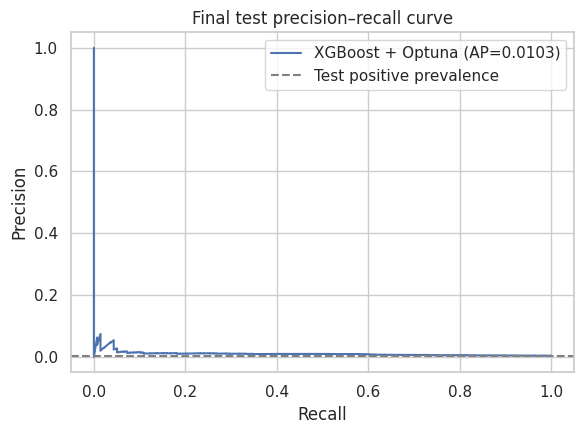

In [26]:
precision, recall, _ = precision_recall_curve(y_test, final_test_scores)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(recall, precision, label=f'{artifact_model_type} (AP={final_test_metrics["average_precision"]:.4f})')
ax.axhline(y_test.mean(), linestyle='--', color='grey', label='Test positive prevalence')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Final test precision–recall curve')
ax.legend()
plt.tight_layout()
plt.show()

Importance method: XGBoost split-based feature importance


,feature,importance
0,act,0.056646
23,sstk,0.042536
32,soft_assets,0.032569
48,missingindicator_ch_cm,0.029133
47,missingindicator_ch_cs,0.027852
3,ceq,0.026153
2,at,0.025576
39,reoa,0.024198
1,ap,0.024072
36,issue,0.023528


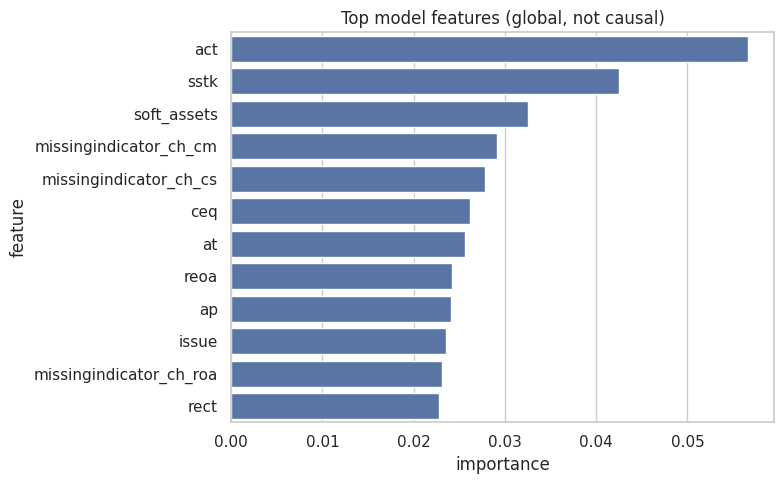

In [27]:
# Global model importance is an inspection aid, not causal evidence.
model_step = final_model.named_steps['model']
feature_names_after_impute = final_model.named_steps['imputer'].get_feature_names_out(feature_cols)
if hasattr(model_step, 'feature_importances_'):
    importances = np.asarray(model_step.feature_importances_)
    importance_method = 'XGBoost split-based feature importance'
elif hasattr(model_step, 'coef_'):
    importances = np.abs(np.asarray(model_step.coef_).ravel())
    importance_method = 'Absolute standardized Logistic Regression coefficient'
else:
    importances = np.zeros(len(feature_names_after_impute))
    importance_method = 'Unavailable'

importance_df = pd.DataFrame({'feature': feature_names_after_impute, 'importance': importances})
importance_df = importance_df.sort_values('importance', ascending=False)
importance_df.to_csv(ARTIFACT_DIR / 'feature_importance.csv', index=False)
print('Importance method:', importance_method)
display(importance_df.head(15))

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df.head(12), x='importance', y='feature')
plt.title('Top model features (global, not causal)')
plt.tight_layout()
plt.show()

In [28]:
# Export the held-out test review queue for project demonstration. Labels are retained only for evaluation.
scored_test = test_df[[YEAR_COL, COMPANY_COL, TARGET]].copy()
scored_test['risk_score'] = final_test_scores
scored_test['review_rank'] = scored_test['risk_score'].rank(method='first', ascending=False).astype(int)
queue_size = max(1, int(np.ceil(len(scored_test) * 0.05)))
top_queue = scored_test.nsmallest(queue_size, 'review_rank').copy()
top_queue['review_priority'] = 'High-priority review queue (top 5%)'
top_queue.to_csv(ARTIFACT_DIR / 'test_review_queue.csv', index=False)
print(f'Saved top-{queue_size:,} test records to {ARTIFACT_DIR / "test_review_queue.csv"}')
display(top_queue.head(10))

Saved top-1,934 test records to artifacts/test_review_queue.csv


,fyear,gvkey,misstate,risk_score,review_rank,review_priority
140576,2014,3362,0,0.950009,1,High-priority review queue (top 5%)
109625,2008,30170,0,0.926942,2,High-priority review queue (top 5%)
113868,2009,10622,0,0.912386,3,High-priority review queue (top 5%)
144679,2014,171007,0,0.902283,4,High-priority review queue (top 5%)
122998,2010,178083,0,0.893792,5,High-priority review queue (top 5%)
142663,2014,30170,0,0.887775,6,High-priority review queue (top 5%)
135647,2013,12236,0,0.886589,7,High-priority review queue (top 5%)
121375,2010,111864,0,0.881855,8,High-priority review queue (top 5%)
136434,2013,23943,0,0.878502,9,High-priority review queue (top 5%)
108018,2008,7652,0,0.872954,10,High-priority review queue (top 5%)


In [29]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/artifacts",
    "zip",
    "/content/artifacts"
)

files.download("/content/artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final conclusion checklist

Before adding results to a CV or README, fill the summary from the actual notebook run:

1. Report final-test average precision and ROC-AUC without rounding away the scale of the rare-event problem.
2. Report how many labelled positives were in the top 5% review queue, alongside the test-set total and positive prevalence.
3. State whether XGBoost + Optuna beat Logistic Regression on validation and whether the final test result supports the conclusion.
4. Do not claim the system proves fraud, identifies intent, or guarantees detection. It prioritizes historical records for further analyst review.

**Research source:** Bao, Y., Ke, B., Li, B., Yu, Y., & Zhang, J. (2020). *Detecting Accounting Fraud in Publicly Traded U.S. Firms Using a Machine Learning Approach*. Journal of Accounting Research, 58(1), 199–235. Dataset repository: `https://github.com/JarFraud/FraudDetection`.